# Notebook 02b — Depth Estimator: ml-depth-pro (Apple, 2024)

**Purpose:** Run Apple's metric monocular depth model on FoodSeg103, evaluate it with the same protocol as the
classical estimator in **02a_depth_classical.ipynb**, and compare the two. Run 02a first so the comparison has both rows.

Needs the `depth_pro` package (installed from `PVsys/ml-depth-pro`) and `PVsys/checkpoints/depth_pro.pt`.
A GPU is strongly recommended (≈0.5 s/image in fp16; tens of seconds per image on CPU).

---

## 1. What ml-depth-pro Does

Apple's ml-depth-pro (2024) is a Vision Transformer that:
- Processes an image at **multiple scales** (multi-scale patch encoder)
- Predicts **metric depth** (real metres) from a **single image** — no stereo camera needed
- Also regresses the camera **focal length**, removing the need for EXIF metadata
- Trained on millions of labelled + unlabelled images across many datasets

The key breakthrough: metric depth from a single image. Without training, this is mathematically ill-posed — a small object close-up looks identical to a large object far away.

## Evaluation protocol (shared by notebooks 02a and 02b)

FoodSeg103 has **no depth ground truth**, so depth maps are scored against what the dataset does have
(`foodseg_depth.py`; every map is compared at 384 px on its longest side):

| Metric | What it checks | Good value |
|---|---|---|
| `food_auroc` | Does nearness (−depth) separate food pixels from non-food pixels? Food sits on a plate, so it should be nearer the camera. | 1.0 (0.5 = chance) |
| `ring_order` | Fraction of food regions nearer than the ring of surface just around them (9 px band) | 1.0 |
| `height_mm` / `height_ok` | Median height of food above that surrounding surface; fraction of regions with 0 < h ≤ 100 mm. Only meaningful for **metric** depth. | 10–60 mm / 1.0 |
| `boundary_ratio` | Mean ‖∇ log depth‖ on GT region boundaries ÷ elsewhere – do depth edges follow object edges? | > 1 |
| `focal_rel_err` | Estimated focal length vs EXIF `FocalLengthIn35mmFilm` (only the ~3 % of images that still carry it) | 0 |
| `ref_*` | Agreement with **ml-depth-pro** as a pseudo reference, after median scaling: AbsRel, δ<1.25, SI-log, Spearman (all pixels and `ref_food_*` food pixels only) | AbsRel 0, δ1 1, Spearman 1 |
| `sec` | Median runtime per image | – |

Caveats:
- The mask metrics assume food sits *above* the surface around it. That fails for bowls and deep plates (the rim is
  nearer than the food) and for oblique shots, so even a perfect depth map does not reach 1.0.
- They are **necessary, not sufficient**: a map that simply highlights colourful, textured pixels scores well on
  `food_auroc` without encoding any geometry. Read them together with the `ref_*` agreement and the visualisations.
- ml-depth-pro is a strong model but not ground truth; only ~1.5 % of test images carry an EXIF focal length, and it
  assumes the image was resized, not cropped, from the camera original.
Results go to `outputs/depth/<estimator>_test.json`; notebook 02b puts them in one table.

In [ ]:
import math
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm

import foodseg_common as fc
import foodseg_depth as fd

SPLIT      = 'test'
TEST_LIMIT = None    # e.g. 100 for a quick run; None = whole test split (resumable cache)
NAME       = 'depth_pro'

PVSYS_ROOT      = fc.PROJECT_ROOT.parent / 'PVsys'
DEPTH_PRO_REPO  = PVSYS_ROOT / 'ml-depth-pro'
CHECKPOINT      = PVSYS_ROOT / 'checkpoints' / 'depth_pro.pt'
assert CHECKPOINT.exists(), f'Depth Pro checkpoint not found: {CHECKPOINT}'

device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
precision = torch.float16 if device.type == 'cuda' else torch.float32
print('device:', device, '| precision:', precision)

device: cuda | precision: torch.float16


In [ ]:
try:
    import depth_pro
except ImportError:
    sys.path.insert(0, str(DEPTH_PRO_REPO / 'src'))
    import depth_pro
from depth_pro.depth_pro import DEFAULT_MONODEPTH_CONFIG_DICT, DepthProConfig

config = DepthProConfig(
    patch_encoder_preset=DEFAULT_MONODEPTH_CONFIG_DICT.patch_encoder_preset,
    image_encoder_preset=DEFAULT_MONODEPTH_CONFIG_DICT.image_encoder_preset,
    decoder_features=DEFAULT_MONODEPTH_CONFIG_DICT.decoder_features,
    checkpoint_uri=str(CHECKPOINT),
    fov_encoder_preset=DEFAULT_MONODEPTH_CONFIG_DICT.fov_encoder_preset,
    use_fov_head=DEFAULT_MONODEPTH_CONFIG_DICT.use_fov_head,
)
model, transform = depth_pro.create_model_and_transforms(config=config, device=device, precision=precision)
model.eval()
print(f'Depth Pro loaded: {sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parameters, '
      f'network resolution {model.img_size}x{model.img_size}')

Depth Pro loaded: 952 M parameters, network resolution 1536x1536


00005942: 25.01 s | depth 0.450 – 1.433 m | f = 525 px (HFOV 52.0°)


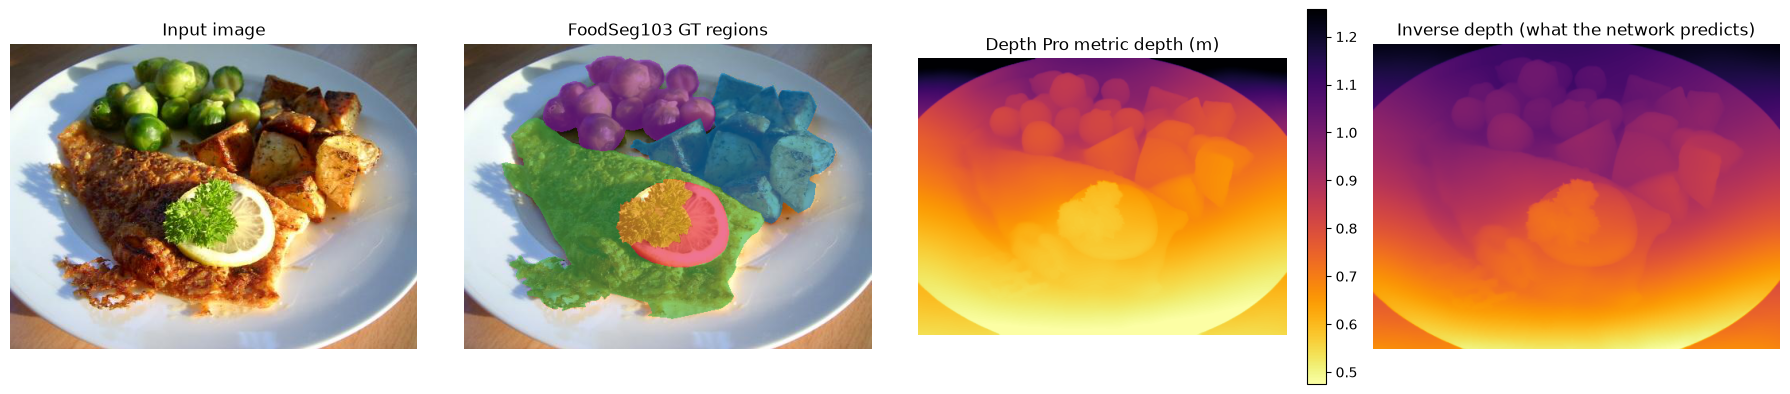

Mask metrics for this image: {'food_auroc': 0.434, 'ring_order': 0.75, 'height_mm': 64.058, 'height_ok': 0.5, 'n_regions': 4, 'boundary_ratio': 2.419, 'median_depth_m': 0.677}


In [ ]:
@torch.no_grad()
def depth_pro_estimate(rgb, sid=None, f_px=None):
    """
    Metric depth (metres, at input resolution) and focal length (px) for one RGB uint8 image.
    f_px=None lets the FOV head predict the focal length; pass a known value (e.g. from EXIF) to fix it.
    """
    x = transform(Image.fromarray(rgb))
    f = None if f_px is None else torch.tensor(float(f_px), device=device)
    pred = model.infer(x, f_px=f)
    return pred['depth'].squeeze().float().cpu().numpy(), float(pred['focallength_px'])

# Demo on the same image as 02a
DEMO_ID = fc.read_split_ids(SPLIT)[0]
rgb = fc.load_rgb(fc.image_path(SPLIT, DEMO_ID))
lm  = fc.load_label_mask(fc.mask_path(SPLIT, DEMO_ID))
t0 = time.perf_counter()
depth_map, f_px = depth_pro_estimate(rgb)
print(f'{DEMO_ID}: {time.perf_counter() - t0:.2f} s | depth {depth_map.min():.3f} – {depth_map.max():.3f} m | '
      f'f = {f_px:.0f} px (HFOV {fd.hfov_deg(f_px, rgb.shape[1]):.1f}°)')

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(rgb); axes[0].set_title('Input image')
axes[1].imshow(fc.overlay(rgb, fc.gt_instances(lm))); axes[1].set_title('FoodSeg103 GT regions')
im = axes[2].imshow(depth_map, cmap='inferno_r', vmin=np.percentile(depth_map, 2), vmax=np.percentile(depth_map, 98))
axes[2].set_title('Depth Pro metric depth (m)'); plt.colorbar(im, ax=axes[2], fraction=0.046)
axes[3].imshow(1 / depth_map, cmap='inferno'); axes[3].set_title('Inverse depth (what the network predicts)')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()
print('Mask metrics for this image:', {k: round(v, 3) for k, v in
      fd.mask_metrics(fd.to_eval(depth_map), fd.eval_label_mask(SPLIT, DEMO_ID)).items()})

## Evaluation on the FoodSeg103 test split

Depth maps are cached at 384 px in `outputs/depth/depth_pro_test.pkl` (resumable — re-running the cell continues where
it stopped). The focal length is **predicted** by the model (no EXIF), so `focal_rel_err` tests the FOV head.

In [ ]:
test_ids = fc.read_split_ids(SPLIT)[:TEST_LIMIT]
cache = fd.run_depth(depth_pro_estimate, SPLIT, test_ids, name=NAME, progress=tqdm)

exif = fd.exif_focals(SPLIT, test_ids)
summary, rows = fd.evaluate(cache, SPLIT, exif=exif)
fd.save_result(NAME, SPLIT, summary, extra=dict(precision=str(precision), device=str(device)))
per_image = pd.DataFrame(rows).set_index('id')
print(f'{len(cache)} images, {len(exif)} with EXIF focal length')
pd.Series(summary).round(4).to_frame(NAME)

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


  0%|          | 0/1069 [00:00<?, ?it/s]

KeyboardInterrupt: 

### Known focal length (EXIF subset)

The PVsys pipeline passes the EXIF focal length to Depth Pro when it exists. On the test images that still carry it,
compare the model's own focal estimate with the EXIF-fixed run: how much does knowing the focal length change the
metric scale (median depth) and the mask metrics?

In [ ]:
if exif:
    exif_ids = list(exif)
    fixed = fd.run_depth(lambda rgb, sid: depth_pro_estimate(rgb, f_px=exif[sid]), SPLIT, exif_ids,
                         name=NAME + '_exif', progress=tqdm)
    s_fixed, rows_fixed = fd.evaluate(fixed, SPLIT, ref_cache=cache)
    s_pred, _ = fd.evaluate({s: cache[s] for s in exif_ids}, SPLIT, exif=exif)
    fd.save_result(NAME + '_exif', SPLIT, s_fixed, extra=dict(note='EXIF focal length given; EXIF subset only'))
    scale = [np.median(fixed[s]['depth'].astype(np.float32)) / np.median(cache[s]['depth'].astype(np.float32))
             for s in exif_ids]
    print(f'{len(exif_ids)} images | predicted-focal error vs EXIF: {s_pred["focal_rel_err"]:.1%} | '
          f'median depth ratio (EXIF / predicted focal): {np.median(scale):.3f}')
    display(pd.DataFrame({'predicted focal': s_pred, 'EXIF focal': s_fixed}).loc[
        ['food_auroc', 'ring_order', 'height_mm', 'height_ok', 'boundary_ratio', 'median_depth_m']].round(3))
else:
    print('No test images with EXIF focal length in this selection.')

### Agreement of the classical estimator with Depth Pro

With Depth Pro as a pseudo reference, re-score the cached classical depth maps from 02a (scale-invariant: the classical
map is median-scaled to Depth Pro first). This updates `outputs/depth/classical_test.json` with the `ref_*` columns.

In [ ]:
classical = fd.load_depth_cache('classical', SPLIT)
classical = {s: classical[s] for s in test_ids if s in classical}
if classical:
    old = fd.load_results(SPLIT).get('classical', {})
    s_cl, rows_cl = fd.evaluate(classical, SPLIT, ref_cache=cache, exif=exif)
    fd.save_result('classical', SPLIT, s_cl, extra={k: old[k] for k in ('weights', 'fov_deg', 'plate_distance_m') if k in old})
    agree = pd.DataFrame(rows_cl).set_index('id')
    print(f'{len(classical)} classical maps scored against Depth Pro')
    display(pd.Series({k: v for k, v in s_cl.items() if k.startswith('ref_')}).round(4).to_frame('classical vs Depth Pro'))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    axes[0].hist(agree['ref_spearman'].dropna(), bins=40); axes[0].axvline(0, color='k', ls='--')
    axes[0].set_title('Spearman ρ (classical, Depth Pro) per image')
    axes[1].hist(agree['ref_abs_rel'].dropna(), bins=40); axes[1].set_title('AbsRel after median scaling')
    plt.tight_layout(); plt.show()
else:
    print('No classical cache found — run 02a_depth_classical.ipynb first.')

### Testing the classical priors with Depth Pro

The classical estimator assumes a **70° horizontal FOV** and a **0.5 m** median camera distance. Depth Pro predicts
both per image, so we can check whether those priors fit FoodSeg103.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(per_image['hfov_deg'], bins=40); axes[0].axvline(70, color='tab:red', lw=2, label='classical prior 70°')
axes[0].set_title('Depth Pro horizontal FOV (°)'); axes[0].legend()
axes[1].hist(per_image['median_depth_m'].clip(upper=3), bins=40)
axes[1].axvline(0.5, color='tab:red', lw=2, label='classical prior 0.5 m')
axes[1].set_title('Depth Pro median scene depth (m, clipped at 3)'); axes[1].legend()
if exif:
    f_ex = np.array([exif[s] for s in per_image.index if s in exif])
    f_dp = per_image.loc[[s for s in per_image.index if s in exif], 'f_px'].values
    axes[2].scatter(f_ex, f_dp, s=12); lim = [0, max(f_ex.max(), f_dp.max()) * 1.05]
    axes[2].plot(lim, lim, 'k--', lw=1); axes[2].set_xlim(lim); axes[2].set_ylim(lim)
    axes[2].set_xlabel('EXIF focal (px)'); axes[2].set_ylabel('Depth Pro focal (px)')
axes[2].set_title('Predicted vs EXIF focal length')
plt.tight_layout(); plt.show()
print(f"HFOV median {per_image['hfov_deg'].median():.1f}° | median depth median {per_image['median_depth_m'].median():.3f} m")

## Comparison: classical vs ml-depth-pro

Every saved result in `outputs/depth/*_test.json` (02a writes `classical`, this notebook `depth_pro` and, on the EXIF
subset only, `depth_pro_exif` — note its smaller `n_images`). Written to `outputs/depth/comparison_test.csv/.png`.

In [ ]:
results = fd.load_results(SPLIT)
COLS = ['n_images', 'food_auroc', 'ring_order', 'height_mm', 'height_ok', 'boundary_ratio', 'median_depth_m',
        'hfov_deg', 'focal_rel_err', 'n_focal', 'ref_abs_rel', 'ref_delta1', 'ref_spearman', 'ref_food_spearman', 'sec']
table = pd.DataFrame(results).T.reindex(columns=COLS)
table.to_csv(fd.DEPTH_ROOT / f'comparison_{SPLIT}.csv')

plot_cols = [('food_auroc', 0.5), ('ring_order', 0.5), ('height_ok', 0.0), ('boundary_ratio', 1.0)]
fig, axes = plt.subplots(1, len(plot_cols), figsize=(16, 3.8))
for ax, (col, chance) in zip(axes, plot_cols):
    s = table[col].astype(float)
    ax.bar(s.index, s.values, color=['tab:orange' if i == 'classical' else 'tab:blue' for i in s.index])
    ax.axhline(chance, color='k', ls='--', lw=1); ax.set_title(col); ax.tick_params(axis='x', rotation=20)
plt.suptitle(f'Depth estimators on FoodSeg103 {SPLIT} (dashed = chance / no signal)')
plt.tight_layout(); plt.savefig(fd.DEPTH_ROOT / f'comparison_{SPLIT}.png', dpi=120); plt.show()
table.astype(float).round(3)

In [ ]:
# Qualitative: same test images, both estimators (yellow = near; each map uses its own colour range)
classical = fd.load_depth_cache('classical', SPLIT)
rng = np.random.default_rng(0)
show = [s for s in rng.permutation(list(cache)) if s in classical][:5] or list(cache)[:5]
cols = 4 if classical else 3
fig, axes = plt.subplots(len(show), cols, figsize=(4 * cols, 3.3 * len(show)), squeeze=False)
for row, sid in zip(axes, show):
    lm = fd.eval_label_mask(SPLIT, sid)
    img = cv2.resize(fc.load_rgb(fc.image_path(SPLIT, sid)), lm.shape[::-1], interpolation=cv2.INTER_AREA)
    panels = [(img, sid), (fc.overlay(img, fc.gt_instances(lm, min_area=1)), 'GT regions')]
    if classical:
        panels.append((fd.colourise(classical[sid]['depth'].astype(np.float32)), 'classical'))
    panels.append((fd.colourise(cache[sid]['depth'].astype(np.float32)), 'ml-depth-pro'))
    for ax, (im, title) in zip(row, panels):
        ax.imshow(im); ax.set_title(title, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
# Metric 3D point cloud of the food (Depth Pro depth + its own focal length), demo image
d = cache[DEMO_ID]['depth'].astype(np.float32)
lm_e = fd.eval_label_mask(SPLIT, DEMO_ID)
f_eval = cache[DEMO_ID]['f_px'] * d.shape[1] / cache[DEMO_ID]['width']     # focal length at the 384 px resolution
fig = plt.figure(figsize=(14, 6))
for k, (mask, title) in enumerate([(None, 'whole image'), (lm_e > 0, 'food pixels only (GT mask)')]):
    pts = fd.backproject(d, f_eval, mask=mask, stride=2)
    ax = fig.add_subplot(1, 2, k + 1, projection='3d')
    ax.scatter(pts[:, 0], pts[:, 2], -pts[:, 1], c=pts[:, 2], cmap='plasma_r', s=1, alpha=0.6)
    ax.set_xlabel('X (m)'); ax.set_ylabel('Z depth (m)'); ax.set_zlabel('Y (m)')
    ax.set_title(f'Depth Pro point cloud — {title}\n{len(pts):,} points', fontsize=11)
plt.tight_layout(); plt.show()

## Classical vs Depth Pro — summary

The measured numbers are in the comparison table above; the qualitative trade-offs:

| Aspect | Classical (this notebook) | ml-depth-pro |
|---|---|---|
| Metric depth | Approximate (scale anchor) | True metric |
| FOV estimation | Requires prior or EXIF | Predicted by model |
| Novel scenes | Breaks down | Generalises |
| GPU required | No | Recommended |
| Inference time | < 100 ms CPU | ~200–500 ms GPU |
| Explainability | Full — each cue is interpretable | Black-box |
| Best for | Constrained domain (food, 50 cm) | Any scene |

> **The fundamental lesson:** Classical methods are interpretable and fast for constrained problems. Neural networks buy you generality at the cost of interpretability and compute.